# 0. Preparação

## 0.1 Importações

In [1]:
import os, re, io, csv, glob, zipfile, difflib, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from google.colab import drive
import pyogrio
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from libpysal.weights import Queen, fuzzy_contiguity
from esda.moran import Moran, Moran_Local
from scipy.stats import linregress

## 0.2 Configuração

In [2]:
drive.mount('/content/drive')

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 200)

PASTA = '/content/drive/MyDrive/Dados'     # pasta do print
SAIDA = os.path.join(PASTA, 'saida')
os.makedirs(SAIDA, exist_ok=True)

Mounted at /content/drive


In [3]:
CRS_METROS = 'EPSG:31983'   # SIRGAS 2000 / UTM 23S
CRS_MAPA   = 'EPSG:4326'    # WGS84 (lat/lon) para o Power BI
SEED = 42
RAIO_M = 2000               # raio da contagem de serviços (P2)

ARQ = {
    'distritos':  'geosampa_distritos_96.geojson',
    'censo':      'censo-sub-distr_1950-2022.xlsx',
    'cadunico':   'smads_cadunico_distrito_2026-01.csv',
    'cde':        'cde-beneficiarios-rede-basica-2024.csv',
    'cras':       'geosampa_cras.geojson',
    'assist':     'geoportal_equipamento_assistencia_social_v2.geojson',
    'ubs':        'localizacao_UBS.csv',
    'cartorios':  'localizacao_cartorios_capital.xlsx',
    'poupatempo': 'localizacao_poupatempo_capital.xlsx',
    'risco':      'SIRGAS_GPKG_riscogeologicoatual.zip',
}

# Deixe None para detecção automática. Se a célula de inspeção mostrar que a
# detecção errou, escreva aqui o nome exato da coluna.
COL = {
    'distrito_nome': None,   # geosampa_distritos_96: nome do distrito
    'distrito_cod':  None,   # geosampa_distritos_96: código do distrito
    'censo_nome':    None,   # censo: coluna com os nomes
    'censo_pop':     None,   # censo: coluna de 2022
    'cad_nome':      None,   # cadunico: coluna com o distrito
    'cad_valor':     None,   # cadunico: pessoas (ou famílias) cadastradas
    'cde_munic':     None,   # cde: município
    'cde_valor':     None,   # cde: quantidade de beneficiários
    'risco_grau':    None,   # risco: coluna com R1..R4
}
CAMADA_RISCO = None   # nome da camada dentro do GeoPackage (None = escolhe a de polígonos)
ABA_CENSO = None      # aba do Excel do censo (None = primeira)

## 0.3 Funções auxiliares (nomes, leitura, coordenadas)

In [4]:
try:
    from unidecode import unidecode
except ImportError:                      # reserva, caso a instalação falhe
    import unicodedata
    def unidecode(s):
        return unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode()

# ---------- nomes de distrito ----------
ABREV = [(r'^JD ', 'JARDIM '), (r'^VL ', 'VILA '), (r'^STA ', 'SANTA '), (r'^STO ', 'SANTO '),
         (r'^PQ ', 'PARQUE '), (r'^CID ', 'CIDADE '), (r'^S ', 'SAO ')]
ALIAS = {'SAO MIGUEL PAULISTA': 'SAO MIGUEL', 'JARDIM SAO LUIZ': 'JARDIM SAO LUIS',
         'ARTHUR ALVIM': 'ARTUR ALVIM', 'GUAIANAZES': 'GUAIANASES', 'MOOCA': 'MOOCA',
         'FREGUESIA': 'FREGUESIA DO O', 'BRASILANDIA VILA': 'BRASILANDIA'}

def norm(txt):
    # MAIÚSCULAS, sem acento, sem pontuação, abreviações expandidas
    if txt is None or (isinstance(txt, float) and np.isnan(txt)):
        return None
    s = unidecode(str(txt)).upper().strip().replace("'", '').replace('`', '')
    s = re.sub(r'[^A-Z0-9 ]', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    s = re.sub(r'^(DISTRITO|DIST|DS) ', '', s)
    s = re.sub(r'^\d+\s*', '', s)          # tira numeração na frente
    for pat, rep in ABREV:
        s = re.sub(pat, rep, s)
    return ALIAS.get(s, s) or None

# 32 subprefeituras e seus 96 distritos (Lei 13.399/2002 + Sapopemba, 2013).
# Serve como lista oficial para validar os nomes e para o filtro por gestor (RLS).
SUBPREF = {
    'Aricanduva/Formosa/Carrão': ['Aricanduva', 'Carrão', 'Vila Formosa'],
    'Butantã': ['Butantã', 'Morumbi', 'Raposo Tavares', 'Rio Pequeno', 'Vila Sônia'],
    'Campo Limpo': ['Campo Limpo', 'Capão Redondo', 'Vila Andrade'],
    'Capela do Socorro': ['Cidade Dutra', 'Grajaú', 'Socorro'],
    'Casa Verde/Cachoeirinha': ['Cachoeirinha', 'Casa Verde', 'Limão'],
    'Cidade Ademar': ['Cidade Ademar', 'Pedreira'],
    'Cidade Tiradentes': ['Cidade Tiradentes'],
    'Ermelino Matarazzo': ['Ermelino Matarazzo', 'Ponte Rasa'],
    'Freguesia/Brasilândia': ['Brasilândia', 'Freguesia do Ó'],
    'Guaianases': ['Guaianases', 'Lajeado'],
    'Ipiranga': ['Cursino', 'Ipiranga', 'Sacomã'],
    'Itaim Paulista': ['Itaim Paulista', 'Vila Curuçá'],
    'Itaquera': ['Cidade Líder', 'Itaquera', 'José Bonifácio', 'Parque do Carmo'],
    'Jabaquara': ['Jabaquara'],
    'Jaçanã/Tremembé': ['Jaçanã', 'Tremembé'],
    'Lapa': ['Barra Funda', 'Jaguara', 'Jaguaré', 'Lapa', 'Perdizes', 'Vila Leopoldina'],
    "M'Boi Mirim": ['Jardim Ângela', 'Jardim São Luís'],
    'Mooca': ['Água Rasa', 'Belém', 'Brás', 'Mooca', 'Pari', 'Tatuapé'],
    'Parelheiros': ['Marsilac', 'Parelheiros'],
    'Penha': ['Artur Alvim', 'Cangaíba', 'Penha', 'Vila Matilde'],
    'Perus': ['Anhanguera', 'Perus'],
    'Pinheiros': ['Alto de Pinheiros', 'Itaim Bibi', 'Jardim Paulista', 'Pinheiros'],
    'Pirituba/Jaraguá': ['Jaraguá', 'Pirituba', 'São Domingos'],
    'Santana/Tucuruvi': ['Mandaqui', 'Santana', 'Tucuruvi'],
    'Santo Amaro': ['Campo Belo', 'Campo Grande', 'Santo Amaro'],
    'São Mateus': ['Iguatemi', 'São Mateus', 'São Rafael'],
    'São Miguel': ['Jardim Helena', 'São Miguel', 'Vila Jacuí'],
    'Sapopemba': ['Sapopemba'],
    'Sé': ['Bela Vista', 'Bom Retiro', 'Cambuci', 'Consolação', 'Liberdade', 'República', 'Santa Cecília', 'Sé'],
    'Vila Maria/Vila Guilherme': ['Vila Guilherme', 'Vila Maria', 'Vila Medeiros'],
    'Vila Mariana': ['Moema', 'Saúde', 'Vila Mariana'],
    'Vila Prudente': ['São Lucas', 'Vila Prudente'],
}
MAPA_SUB = {norm(d): (d, s) for s, ds in SUBPREF.items() for d in ds}
NOMES_OFICIAIS = sorted(MAPA_SUB)
assert len(NOMES_OFICIAIS) == 96, len(NOMES_OFICIAIS)

LOG_CASAMENTO = []
def casar_nome(txt, cutoff=0.85):
    # devolve a chave oficial (nome normalizado) ou None
    n = norm(txt)
    if not n:
        return None
    if n in MAPA_SUB:
        return n
    m = difflib.get_close_matches(n, NOMES_OFICIAIS, n=1, cutoff=cutoff)
    if m:
        LOG_CASAMENTO.append((str(txt), m[0]))
        return m[0]
    return None

# ---------- leitura de tabelas ----------
def ler_csv_bruto(p):
    txt = None
    for enc in ('utf-8-sig', 'latin-1'):
        try:
            with open(p, encoding=enc) as f:
                txt = f.read()
            break
        except UnicodeDecodeError:
            continue
    amostra = '\n'.join(txt.splitlines()[:50])
    try:
        sep = csv.Sniffer().sniff(amostra, delimiters=';,\t|').delimiter
    except csv.Error:
        sep = max([';', ',', '\t', '|'], key=amostra.count)
    linhas = list(csv.reader(io.StringIO(txt), delimiter=sep))
    w = max(len(l) for l in linhas)
    return pd.DataFrame([l + [None] * (w - len(l)) for l in linhas])

def com_cabecalho(raw):
    # acha a linha de cabeçalho (pula títulos e notas no topo)
    raw = raw.replace({'': None}).dropna(how='all').dropna(axis=1, how='all').reset_index(drop=True)
    cheios = raw.notna().sum(axis=1)
    i = int((cheios >= 0.8 * cheios.max()).idxmax())
    cols, vistos = [], {}
    for j, c in enumerate(raw.iloc[i]):
        c = str(c).strip() if c is not None and str(c) != 'nan' else f'col_{j}'
        c = re.sub(r'\.0$', '', c)            # 2022.0 -> 2022
        vistos[c] = vistos.get(c, 0) + 1
        cols.append(c if vistos[c] == 1 else f'{c}_{vistos[c]}')
    df = raw.iloc[i + 1:].copy()
    df.columns = cols
    return df.reset_index(drop=True)

def ler_tabela(chave, aba=None):
    p = os.path.join(PASTA, ARQ[chave])
    if p.lower().endswith(('.xlsx', '.xls')):
        abas = pd.read_excel(p, sheet_name=None, header=None)
        nome = aba or list(abas)[0]
        if len(abas) > 1:
            print(f'  {ARQ[chave]}: abas {list(abas)} -> usando "{nome}"')
        return com_cabecalho(abas[nome])
    return com_cabecalho(ler_csv_bruto(p))

def col_por_nome(df, *chaves, excluir=()):
    for c in df.columns:
        cn = norm(c) or ''
        if any(k in cn for k in chaves) and not any(e in cn for e in excluir):
            return c
    return None

def col_de_nomes(df):
    # coluna que mais casa com os 96 nomes oficiais
    melhor, hits = None, 0
    for c in df.columns:
        if df[c].dtype.kind in 'if':
            continue
        h = df[c].dropna().astype(str).map(lambda x: norm(x) in MAPA_SUB).sum()
        if h > hits:
            melhor, hits = c, h
    return melhor

def para_num(s):
    # converte '1.234', '1.234,5', '1234' etc. em número
    if s.dtype.kind in 'if':
        return s
    s = s.astype(str).str.strip().str.replace(r'\s', '', regex=True)
    if s.str.contains(',', regex=False).any():
        s = s.str.replace('.', '', regex=False).str.replace(',', '.', regex=False)
    elif s.str.fullmatch(r'-?\d{1,3}(\.\d{3})+').any():
        s = s.str.replace('.', '', regex=False)
    return pd.to_numeric(s, errors='coerce')

def para_coord(s):
    return pd.to_numeric(s.astype(str).str.strip().str.replace(',', '.', regex=False), errors='coerce')

def ler_geo(caminho):
    # lê GeoJSON/GPKG/SHP; se o arquivo não for um GeoJSON válido, tenta
    # recuperar (ZIP, JSON sem "type", CSV com lat/lon) e, se não der, mostra
    # o início do arquivo e devolve vazio em vez de travar o notebook
    try:
        return gpd.read_file(caminho)
    except Exception as e:
        print(f'  {os.path.basename(caminho)}: não abriu direto ({type(e).__name__})')
    tam = os.path.getsize(caminho)
    with open(caminho, 'rb') as f:
        ini = f.read(400)
    print(f'  tamanho: {tam} bytes | início do arquivo: {ini[:200]!r}')
    if ini[:2] == b'PK':                                   # na verdade é um .zip
        return gpd.read_file('zip://' + caminho)
    try:
        import json
        js = json.load(open(caminho, encoding='utf-8-sig'))
        feats = js.get('features') if isinstance(js, dict) else js
        if feats and isinstance(feats, list) and 'geometry' in feats[0]:
            crs = CRS_METROS if 'EPSG::31983' in str(js.get('crs', '')) else None
            return gpd.GeoDataFrame.from_features(feats, crs=crs)
        if feats and isinstance(feats, list):              # lista de registros com lat/lon
            return pd.DataFrame(feats)
    except Exception:
        pass
    try:
        return com_cabecalho(ler_csv_bruto(caminho))        # CSV salvo com extensão .geojson
    except Exception:
        pass
    print('  -> arquivo inválido (HTML de erro, download incompleto ou vazio). Baixe de novo.')
    return gpd.GeoDataFrame(geometry=[], crs=CRS_METROS)

def salvar(df, nome):
    # CSV para Power BI em pt-BR: separador ';' e decimal ','
    df = pd.DataFrame(df.drop(columns='geometry', errors='ignore'))
    caminho = os.path.join(SAIDA, f'{nome}.csv')
    df.to_csv(caminho, sep=';', decimal=',', index=False, encoding='utf-8-sig')
    print(f'  salvo {nome}.csv  ({len(df)} linhas)')

## 0.4 Funções geográfica

In [5]:
def uniao(g):
    return g.geometry.union_all() if hasattr(g.geometry, 'union_all') else g.geometry.unary_union

def garantir_crs(g):
    if g.crs is None:     # sem CRS no arquivo: deduz pelas coordenadas
        g = g.set_crs(CRS_METROS if abs(g.total_bounds[0]) > 1000 else CRS_MAPA)
    g = g.to_crs(CRS_METROS)
    g['geometry'] = g.geometry.make_valid() if hasattr(g.geometry, 'make_valid') else g.buffer(0)
    return g

def geocodificar(df, nome):
    # Só usado se a planilha não tiver latitude/longitude. Usa OpenStreetMap
    # (1 consulta por segundo) e guarda o resultado em saida/geocode_<nome>.csv.
    from geopy.geocoders import Nominatim
    from geopy.extra.rate_limiter import RateLimiter
    cache = os.path.join(SAIDA, f'geocode_{nome}.csv')
    c_end = col_por_nome(df, 'ENDERE', 'LOGRAD')
    c_num = col_por_nome(df, 'NUMERO', 'NUM ', excluir=('TELEF',))
    c_cep = col_por_nome(df, 'CEP')
    assert c_end, f'{nome}: sem lat/lon e sem coluna de endereço — veja a inspeção'
    df = df.copy()
    partes = df[c_end].astype(str)
    if c_num: partes = partes + ', ' + df[c_num].astype(str)
    if c_cep: partes = partes + ', ' + df[c_cep].astype(str)
    df['_consulta'] = partes + ', São Paulo, SP, Brasil'
    if os.path.exists(cache):
        geo = pd.read_csv(cache)
    else:
        geocode = RateLimiter(Nominatim(user_agent='caminho-dos-direitos-fiap').geocode, min_delay_seconds=1.1)
        res = []
        for q in df['_consulta'].unique():
            loc = geocode(q)
            if loc is None:   # tenta só a rua + CEP
                loc = geocode(re.sub(r',[^,]*,', ',', q, count=1))
            res.append((q, loc.latitude if loc else None, loc.longitude if loc else None))
        geo = pd.DataFrame(res, columns=['_consulta', 'lat', 'lon'])
        geo.to_csv(cache, index=False)
    df = df.merge(geo, on='_consulta', how='left')
    print(f'  {nome}: geocodificados {df.lat.notna().sum()}/{len(df)}')
    df = df.dropna(subset=['lat', 'lon'])
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.lon, df.lat), crs=CRS_MAPA)

def para_pontos(obj, nome):
    # tabela ou GeoDataFrame -> pontos em EPSG:31983 com coluna nome_servico
    if isinstance(obj, gpd.GeoDataFrame):
        g = obj
    else:
        c_lat = col_por_nome(obj, 'LAT')
        c_lon = col_por_nome(obj, 'LON', 'LNG')
        if c_lat and c_lon:
            y, x = para_coord(obj[c_lat]), para_coord(obj[c_lon])
            if y.abs().median() > 30 and x.abs().median() < 30:   # colunas invertidas
                x, y = y, x
            ok = x.notna() & y.notna()
            g = gpd.GeoDataFrame(obj[ok].copy(), geometry=gpd.points_from_xy(x[ok], y[ok]), crs=CRS_MAPA)
        else:
            g = geocodificar(obj, nome)
    g = garantir_crs(g)
    g['geometry'] = g.geometry.representative_point()   # MultiPoint/polígono -> ponto
    c_nome = col_por_nome(g, 'NOME', 'FANTASIA', 'DENOMINA', 'EQUIPAMENTO', 'NM ', 'NO ', 'UNIDADE',
                          excluir=('MUNIC', 'DISTR', 'SUBPREF', 'BAIRRO', 'RESPONS'))
    g['nome_servico'] = g[c_nome].astype(str) if c_nome else [f'{nome} {i+1}' for i in range(len(g))]
    return g

In [6]:
# inspeção rápida da CDE (o arquivo usa ';' como separador)
cde_raw = pd.read_csv(os.path.join(PASTA, ARQ['cde']), sep=';', encoding='utf-8-sig', dtype=str)
print(cde_raw.shape); display(cde_raw.head())
for c in ['NomAgente', 'IdcClasseConsumidor', 'IdcTipo', 'DscGrupoTarifario']:
    if c in cde_raw:
        print(f'\n{c}:'); print(cde_raw[c].value_counts().head(10).to_string())

(16367, 10)


,DatGeracaoConjuntoDados,NumAno,NomMes,NomAgente,NumCNPJ,DscGrupoTarifario,IdcClasseConsumidor,IdcTipo,VlrDesconto,VlrCobranca
0,23/07/2026 09:24:34,2024,Janeiro,CASA NOVA II,33541368000116,Rede Básica,9,7,"119730,00",NaN
1,23/07/2026 09:24:34,2024,Janeiro,CASA NOVA III,33541368000116,Rede Básica,9,7,"112461,60",NaN
2,23/07/2026 09:24:34,2024,Janeiro,UTE VERACEL,40551996000148,Rede Básica,9,7,"64071,00",NaN
3,23/07/2026 09:24:34,2024,Janeiro,UTE BOA VISTA,24222394000190,Rede Básica,9,7,"194864,98",NaN
4,23/07/2026 09:24:34,2024,Janeiro,EOL CERRO CHATO I,02016507000169,Rede Básica,9,7,"107866,75",NaN



NomAgente:
NomAgente
RIMA                15
ACAUÃ II            12
TUCANO III          12
SERRA DO MEL IV     12
SERRA DO MEL III    12
SERRA DO MEL VI     12
SERRA DO MEL V      12
BARAÚNAS XV         12
ACAUÃ I             12
FUTURA 21           12

IdcClasseConsumidor:
IdcClasseConsumidor
9     15678
10      689

IdcTipo:
IdcTipo
7    15678
8      689

DscGrupoTarifario:
DscGrupoTarifario
Rede Básica    16364
Fronteira          3


# 1. Tratamento e validação — *as bases batem entre si?*
Padroniza os nomes dos distritos (sem acento, maiúsculas, abreviações), junta tudo pela chave do distrito e confere: **96 linhas**, nenhum distrito sem par e soma da população = total da cidade.

## 1.1 Distritos (GeoSampa)

In [7]:
distritos = garantir_crs(gpd.read_file(os.path.join(PASTA, ARQ['distritos'])))
c_nome = COL['distrito_nome'] or col_de_nomes(distritos)
c_cod  = COL['distrito_cod'] or col_por_nome(distritos, 'CODIGO', 'CD ', 'COD')
print('nome:', c_nome, '| código:', c_cod)

distritos['chave'] = distritos[c_nome].map(casar_nome)
distritos['nome_distrito'] = distritos['chave'].map(lambda k: MAPA_SUB[k][0] if k else None)
distritos['subprefeitura'] = distritos['chave'].map(lambda k: MAPA_SUB[k][1] if k else None)
distritos['cod_distrito'] = (distritos[c_cod].astype(str).str.replace(r'\.0$', '', regex=True)
                             if c_cod else distritos['chave'].rank(method='first').astype(int).astype(str))
distritos['area_km2'] = distritos.area / 1e6

sem_par = distritos[distritos.chave.isna()]
print(f'polígonos: {len(distritos)} | sem par na lista oficial: {len(sem_par)}')
if len(sem_par): display(sem_par[[c_nome]])
assert len(distritos) == 96 and distritos.chave.nunique() == 96, 'Esperado 96 distritos únicos'
print(f'área total da cidade: {distritos.area_km2.sum():,.1f} km²  (oficial ≈ 1.521 km²)')
distritos = distritos[['cod_distrito', 'chave', 'nome_distrito', 'subprefeitura', 'area_km2', 'geometry']]
LIMITE = uniao(distritos).buffer(500)   # cidade + 500 m, para filtrar pontos

nome: ds_nome | código: ds_codigo
polígonos: 96 | sem par na lista oficial: 0
área total da cidade: 1,527.2 km²  (oficial ≈ 1.521 km²)


## 1.2 População (Censo 2022)

In [8]:
censo = ler_tabela('censo', ABA_CENSO)
c_nome = COL['censo_nome'] or col_de_nomes(censo)
c_pop  = COL['censo_pop'] or next((c for c in censo.columns if '2022' in str(c)), None)
print('nome:', c_nome, '| população:', c_pop)

censo['chave'] = censo[c_nome].map(casar_nome)
censo['pop_2022'] = para_num(censo[c_pop])

# Linhas de total da cidade (para conferência)
total_linha = censo[censo[c_nome].astype(str).map(lambda x: bool(re.search(r'TOTAL|MUNICIPIO|MSP|SAO PAULO', norm(x) or '')))]
# Subprefeituras com o mesmo nome de distrito (Sé, Lapa, Mooca...) aparecem 2x:
# o distrito é sempre o menor dos dois valores.
dup = censo.dropna(subset=['chave']).chave.value_counts()
print('nomes repetidos (subprefeitura = distrito):', list(dup[dup > 1].index))
pop = censo.dropna(subset=['chave', 'pop_2022']).groupby('chave', as_index=False)['pop_2022'].min()

print(f'distritos com população: {len(pop)} / 96')
print(f'soma dos 96 distritos: {pop.pop_2022.sum():,.0f}')
if len(total_linha):
    print('linha(s) de total no arquivo:'); display(total_linha[[c_nome, c_pop]])
print('Censo 2022 oficial, município de São Paulo: 11.451.999')

nome: Unidades territoriais | população: 2022
nomes repetidos (subprefeitura = distrito): []
distritos com população: 96 / 96
soma dos 96 distritos: 11,451,999
linha(s) de total no arquivo:


,Unidades territoriais,2022
0,Município de São Paulo,11.451.999


Censo 2022 oficial, município de São Paulo: 11.451.999


## 1.3 CadÚnico por distrito (SMADS)

In [9]:
cad = ler_tabela('cadunico')
c_nome = COL['cad_nome'] or col_de_nomes(cad)
for c in cad.columns:
    if c != c_nome:
        cad[c] = para_num(cad[c]) if para_num(cad[c]).notna().mean() > 0.8 else cad[c]
numericas = [c for c in cad.columns if cad[c].dtype.kind in 'if']
c_val = COL['cad_valor'] or col_por_nome(cad[numericas], 'PESSOA') or col_por_nome(cad[numericas], 'FAMIL') or numericas[0]
print('nome:', c_nome, '| valor usado:', c_val, '\ncolunas numéricas disponíveis:', numericas)

cad['chave'] = cad[c_nome].map(casar_nome)
print('linhas sem distrito reconhecido:', cad[cad.chave.isna()][c_nome].dropna().unique()[:20])
C_VAL_CAD = c_val   # guardado: a célula da CDE reutiliza o nome c_val
if cad.chave.dropna().duplicated().any():
    print('ATENÇÃO: mais de uma linha por distrito -> somando')
cad_d = cad.dropna(subset=['chave']).groupby('chave', as_index=False)[c_val].sum().rename(columns={c_val: 'cadunico'})
print(f'distritos com CadÚnico: {len(cad_d)} / 96 | total: {cad_d.cadunico.sum():,.0f}')

nome: DISTRITO | valor usado: TOTAL POR DISTRITO 
colunas numéricas disponíveis: ['TOTAL POR DISTRITO']
linhas sem distrito reconhecido: []
distritos com CadÚnico: 96 / 96 | total: 1,708,846


## 1.4 Tarifa Social de Energia (ANEEL/CDE) - nível cidade

In [10]:
# ATENÇÃO: este arquivo da ANEEL não tem coluna de município nem de nº de
# beneficiários. Ele traz o valor do desconto (R$) por agente/distribuidora.
# Usamos a distribuidora da capital (Enel SP, antiga Eletropaulo) e, se existir,
# só a classe residencial baixa renda (Tarifa Social). A Enel SP atende 24
# municípios da Grande SP, então o valor é uma APROXIMAÇÃO para a capital.
kpi = {}
try:
    cde = ler_tabela('cde')
    c_ag  = COL['cde_munic'] or col_por_nome(cde, 'MUNIC') or col_por_nome(cde, 'NOMAGENTE', 'AGENTE', 'DISTRIBU')
    c_cls = col_por_nome(cde, 'CLASSE')
    c_val = COL['cde_valor'] or col_por_nome(cde, 'BENEFIC', 'QTD', 'QUANT') or col_por_nome(cde, 'VLRDESCONTO', 'DESCONTO')
    c_ano = col_por_nome(cde, 'NUMANO', 'ANO')
    assert c_ag and c_val, f'colunas não encontradas: {list(cde.columns)}'
    ag = cde[c_ag].astype(str).map(lambda s: norm(s) or '')
    sp = cde[ag.str.contains(r'ENEL.*(SAO PAULO|SP)|ELETROPAULO', regex=True)]
    print('agentes usados:', sp[c_ag].unique()[:5])
    if c_cls:
        cls = sp[c_cls].astype(str).map(lambda s: norm(s) or '')
        if cls.str.contains('BAIXA RENDA').any():
            sp = sp[cls.str.contains('BAIXA RENDA')]
    if c_ano:
        print('anos:', sorted(sp[c_ano].dropna().unique()))
    print('agente:', c_ag, '| classe:', c_cls, '| valor:', c_val, '| linhas:', len(sp))
    display(sp.head())
    nome_kpi = 'tarifa_social_beneficiarios' if 'BENEFIC' in (norm(c_val) or '') else 'cde_desconto_enel_sp_rs'
    kpi[nome_kpi] = float(para_num(sp[c_val]).sum())
    print(f'{nome_kpi} = {kpi[nome_kpi]:,.2f}')
except Exception as e:
    print('CDE não processada — rode a célula de inspeção acima e ajuste COL["cde_munic"]/COL["cde_valor"]:', repr(e))

agentes usados: []
anos: []
agente: NomAgente | classe: IdcClasseConsumidor | valor: VlrDesconto | linhas: 0


,DatGeracaoConjuntoDados,NumAno,NomMes,NomAgente,NumCNPJ,DscGrupoTarifario,IdcClasseConsumidor,IdcTipo,VlrDesconto,VlrCobranca


cde_desconto_enel_sp_rs = 0.00


## 1.5 Pontos de serviço (CRAS, UBS, cartórios, Poupatempo)

In [11]:
def dentro_da_cidade(g, nome):
    n0 = len(g)
    g = g[g.within(LIMITE)].copy()
    print(f'  {nome}: {n0} lidos -> {len(g)} dentro da cidade')
    return g

# CRAS: o arquivo do GeoSampa veio com erro do servidor -> fonte = Geoportal (SMADS)
assist = gpd.read_file(os.path.join(PASTA, ARQ['assist']))
cras_geo = assist[assist['nm_classe_equipamento'].str.contains('- CRAS', regex=False)].copy()
cras = dentro_da_cidade(para_pontos(cras_geo, 'CRAS'), 'CRAS Geoportal')
cras['nome_servico'] = 'CRAS - ' + cras['tx_endereco_equipamento'].str.title()
print(f'  -> CRAS usados: {len(cras)}')

# UBS (CNES): mantém só UBS/Centro de Saúde se houver coluna de tipo
ubs_raw = ler_tabela('ubs')
c_tipo = col_por_nome(ubs_raw, 'TIPO', 'TP UNID', 'DS TIPO')
if c_tipo:
    m = ubs_raw[c_tipo].astype(str).map(lambda s: norm(s) or '').str.contains('UBS|BASICA|CENTRO DE SAUDE', regex=True)
    if m.any():
        ubs_raw = ubs_raw[m]
ubs = dentro_da_cidade(para_pontos(ubs_raw, 'UBS'), 'UBS')
cartorios = dentro_da_cidade(para_pontos(ler_tabela('cartorios'), 'Cartório'), 'Cartórios')
poupatempo = dentro_da_cidade(para_pontos(ler_tabela('poupatempo'), 'Poupatempo'), 'Poupatempo')

SERVICOS = {'CRAS': cras, 'UBS': ubs, 'Cartório': cartorios, 'Poupatempo': poupatempo}
SLUG = {'CRAS': 'cras', 'UBS': 'ubs', 'Cartório': 'cartorio', 'Poupatempo': 'poupatempo'}

# dim_servico: um ponto por linha, com o distrito onde está
pts = []
for tipo, g in SERVICOS.items():
    if len(g) == 0:
        continue
    p = g[['nome_servico', 'geometry']].copy(); p['tipo_servico'] = tipo
    pts.append(p)
dim_servico = gpd.GeoDataFrame(pd.concat(pts, ignore_index=True), crs=CRS_METROS)
dim_servico = gpd.sjoin(dim_servico, distritos[['cod_distrito', 'geometry']], how='left', predicate='within').drop(columns='index_right')
# Pontos que caíram fora dos polígonos (o filtro usa cidade + 500 m):
# na divisa (até 100 m, erro de coordenada) recebem o distrito mais próximo; o resto é de outro município
sem = dim_servico.cod_distrito.isna()
if sem.any():
    perto = gpd.sjoin_nearest(dim_servico.loc[sem].drop(columns='cod_distrito'), distritos[['cod_distrito', 'geometry']],
                              how='left', max_distance=100)
    perto = perto[~perto.index.duplicated()]
    dim_servico.loc[sem, 'cod_distrito'] = perto.cod_distrito
    print(f'  pontos fora dos distritos: {sem.sum()} | na divisa (até 100 m), com distrito: {perto.cod_distrito.notna().sum()}'
          f' | fora do município: {dim_servico.cod_distrito.isna().sum()}')
ll = dim_servico.to_crs(CRS_MAPA)
dim_servico['lat'], dim_servico['lon'] = ll.geometry.y.round(6), ll.geometry.x.round(6)
dim_servico.insert(0, 'id_servico', range(1, len(dim_servico) + 1))
display(dim_servico.groupby('tipo_servico').size().rename('qtd'))

  CRAS Geoportal: 54 lidos -> 54 dentro da cidade
  -> CRAS usados: 54
  UBS: 46120 lidos -> 581 dentro da cidade
  localizacao_cartorios_capital.xlsx: abas ['Cartórios SP Capital', 'Fonte e notas'] -> usando "Cartórios SP Capital"
  Cartórios: 58 lidos -> 58 dentro da cidade
  Poupatempo: 11 lidos -> 11 dentro da cidade
  pontos fora dos distritos: 36 | na divisa (até 100 m), com distrito: 4 | fora do município: 32


,qtd
tipo_servico,
CRAS,54
Cartório,58
Poupatempo,11
UBS,581


## 1.6 Juntar e validar

In [12]:
dim_distrito = (distritos.merge(pop, on='chave', how='left')
                         .merge(cad_d, on='chave', how='left'))
dim_distrito['cad_por_mil'] = dim_distrito.cadunico / dim_distrito.pop_2022 * 1000
dim_distrito['densidade_hab_km2'] = dim_distrito.pop_2022 / dim_distrito.area_km2

checks = {
    '96 distritos': len(dim_distrito) == 96,
    'chave única': dim_distrito.cod_distrito.is_unique,
    'população em todos': dim_distrito.pop_2022.notna().all(),
    'CadÚnico em todos': dim_distrito.cadunico.notna().all(),
    'CadÚnico <= população': (dim_distrito.cadunico <= dim_distrito.pop_2022).all(),
}
for k, v in checks.items():
    print(('OK   ' if v else 'FALHA'), k)
faltam = dim_distrito[dim_distrito[['pop_2022', 'cadunico']].isna().any(axis=1)]
if len(faltam): display(faltam[['nome_distrito', 'pop_2022', 'cadunico']])
if LOG_CASAMENTO:
    print('\nNomes casados por semelhança (confira!):')
    display(pd.DataFrame(sorted(set(LOG_CASAMENTO)), columns=['original', 'casado_com']))

kpi.update({'populacao_2022': dim_distrito.pop_2022.sum(), 'cadunico_total': dim_distrito.cadunico.sum(),
            'qtd_cras': len(cras), 'qtd_ubs': len(ubs), 'qtd_cartorios': len(cartorios), 'qtd_poupatempo': len(poupatempo)})
display(pd.Series(kpi, name='cidade'))
display(dim_distrito.drop(columns='geometry').describe().T)

OK    96 distritos
OK    chave única
OK    população em todos
OK    CadÚnico em todos
OK    CadÚnico <= população


,cidade
cde_desconto_enel_sp_rs,0.0
populacao_2022,11451999.0
cadunico_total,1708846.0
qtd_cras,54.0
qtd_ubs,581.0
qtd_cartorios,58.0
qtd_poupatempo,11.0


,count,mean,std,min,25%,50%,75%,max
area_km2,96.0,15.907959,26.961270,2.193568,7.396561,9.780277,13.563480,208.174312
pop_2022,96.0,119291.656250,69608.520254,11443.000000,75489.750000,103611.500000,144560.750000,384873.000000
cadunico,96.0,17800.479167,15655.386071,655.000000,6296.000000,11554.500000,26409.250000,77270.000000
cad_por_mil,96.0,140.009130,82.520564,7.997656,87.708392,134.119163,182.717578,604.481370
densidade_hab_km2,96.0,10986.584705,4783.995585,54.968357,8067.481105,10679.296995,13804.656206,25334.438178


## P2. Acesso aos serviços — *quão longe cada distrito está do CRAS, UBS, cartório e Poupatempo?*
Do **centroide** de cada distrito, em metros (EPSG:31983): distância ao serviço mais próximo (`sjoin_nearest`), quantidade em 2 km e quantidade dentro do distrito.

In [13]:
centro = distritos[['cod_distrito', 'geometry']].copy()
centro['geometry'] = distritos.geometry.centroid
fora = ~centro.within(distritos.geometry)
if fora.any():
    print('centroide fora do próprio distrito (formato irregular):', list(distritos.loc[fora, 'nome_distrito']))
circulo = centro.copy(); circulo['geometry'] = centro.buffer(RAIO_M)

linhas = []
for tipo, g in SERVICOS.items():
    if len(g) == 0:
        print('sem pontos para', tipo); continue
    p = g[['nome_servico', 'geometry']]
    perto = (gpd.sjoin_nearest(centro, p, how='left', distance_col='dist_m')
               .drop_duplicates('cod_distrito')[['cod_distrito', 'nome_servico', 'dist_m']])
    n_raio = gpd.sjoin(circulo, p, predicate='intersects').groupby('cod_distrito').size()
    n_dist = gpd.sjoin(distritos[['cod_distrito', 'geometry']], p, predicate='intersects').groupby('cod_distrito').size()
    perto['servico'] = tipo
    perto['qtd_2km'] = perto.cod_distrito.map(n_raio).fillna(0).astype(int)
    perto['qtd_no_distrito'] = perto.cod_distrito.map(n_dist).fillna(0).astype(int)
    linhas.append(perto)

fato_acesso = pd.concat(linhas, ignore_index=True).rename(columns={'nome_servico': 'servico_mais_proximo'})
fato_acesso['dist_km'] = (fato_acesso.pop('dist_m') / 1000).round(3)
fato_acesso = fato_acesso[['cod_distrito', 'servico', 'servico_mais_proximo', 'dist_km', 'qtd_2km', 'qtd_no_distrito']]

display(fato_acesso.groupby('servico')[['dist_km', 'qtd_2km']].describe().round(2))
dist_wide = (fato_acesso.pivot(index='cod_distrito', columns='servico', values='dist_km')
                        .rename(columns=lambda s: f'dist_{SLUG[s]}_km'))

dist_km                                            qtd_2km                                      
             count  mean   std   min   25%   50%   75%    max   count  mean   std  min  25%  50%  75%   max
servico                                                                                                    
CRAS          96.0  2.04  1.15  0.19  1.16  2.00  2.75   5.27    96.0  0.56  0.63  0.0  0.0  0.5  1.0   3.0
Cartório      96.0  2.32  2.05  0.18  0.93  1.79  2.98  13.84    96.0  1.06  1.35  0.0  0.0  1.0  1.0   6.0
Poupatempo    96.0  5.11  4.05  0.27  2.79  4.01  6.34  29.10    96.0  0.17  0.37  0.0  0.0  0.0  0.0   1.0
UBS           96.0  0.63  0.44  0.05  0.35  0.55  0.78   3.16    96.0  6.86  3.96  0.0  4.0  6.5  9.0  21.0

## P3. Risco geológico — *quanto do distrito está em área de risco alto?*
Interseção dos setores de risco com os distritos (`geopandas.overlay`). Para o **% em R3/R4**, os setores R3 e R4 são unidos antes (evita contar duas vezes onde se sobrepõem).

In [14]:
pasta_r = '/content/risco'
with zipfile.ZipFile(os.path.join(PASTA, ARQ['risco'])) as z:
    z.extractall(pasta_r)
arqs = sorted(glob.glob(pasta_r + '/**/*.gpkg', recursive=True) + glob.glob(pasta_r + '/**/*.shp', recursive=True))
print(f'{len(arqs)} arquivos (um por subprefeitura)')

# O zip traz um GeoPackage por subprefeitura: é preciso ler e juntar todos.
partes = []
for a in arqs:
    camadas = pyogrio.list_layers(a)
    camada = CAMADA_RISCO or next((n for n, t in camadas if 'Polygon' in str(t)), camadas[0][0])
    g = garantir_crs(gpd.read_file(a, layer=camada))
    g['arquivo'] = os.path.basename(a)
    partes.append(g)
setores = gpd.GeoDataFrame(pd.concat(partes, ignore_index=True), crs=CRS_METROS)
print(f'{len(setores)} setores no total | colunas: {list(setores.columns)}')

def achar_grau(df):
    cols = [c for c in df.columns if c != 'geometry']
    # 1º colunas com "GRAU" no nome, depois as demais
    cols = sorted(cols, key=lambda c: 'GRAU' not in (norm(c) or ''))
    for c in cols:
        s = df[c].astype(str).str.upper().str.extract(r'R\s*([1-4])')[0]
        if s.notna().mean() > 0.8:
            return c, 'R' + s
        n = pd.to_numeric(df[c], errors='coerce')
        if 'GRAU' in (norm(c) or '') and n.notna().mean() > 0.8 and set(n.dropna().unique()) <= {1, 2, 3, 4}:
            return c, 'R' + n.astype('Int64').astype(str)
    return None, None

if COL['risco_grau']:
    c_grau = COL['risco_grau']
    setores['grau'] = 'R' + setores[c_grau].astype(str).str.upper().str.extract(r'([1-4])')[0]
else:
    c_grau, setores['grau'] = achar_grau(setores)
print('coluna de grau:', c_grau); display(setores.grau.value_counts(dropna=False))
setores = setores[setores.grau.isin(['R1', 'R2', 'R3', 'R4'])].copy()
setores['id_setor'] = range(1, len(setores) + 1)
c_mor = col_por_nome(setores, 'MORADIA')
setores['moradias'] = para_num(setores[c_mor].astype(str)).fillna(0) if c_mor else 0

# fato_risco_setor: um pedaço de setor por distrito
pedacos = gpd.overlay(setores[['id_setor', 'grau', 'geometry']], distritos[['cod_distrito', 'geometry']],
                      how='intersection', keep_geom_type=True)
pedacos['area_m2'] = pedacos.area.round(1)
fato_risco_setor = pedacos[['id_setor', 'cod_distrito', 'grau', 'area_m2']]

# % da área do distrito em R3/R4 (união dos setores)
r34 = setores[setores.grau.isin(['R3', 'R4'])]
alto = uniao(r34)
risco_d = distritos[['cod_distrito']].copy()
risco_d['area_r3r4_km2'] = distritos.geometry.intersection(alto).area / 1e6
risco_d['pct_risco_alto'] = risco_d.area_r3r4_km2 / distritos.area_km2 * 100
risco_d['qtd_setores_r3r4'] = risco_d.cod_distrito.map(
    fato_risco_setor[fato_risco_setor.grau.isin(['R3', 'R4'])].groupby('cod_distrito').id_setor.nunique()).fillna(0).astype(int)
# moradias em R3/R4: cada setor conta no distrito onde está seu ponto interno
pt = r34[['moradias', 'geometry']].copy(); pt['geometry'] = r34.geometry.representative_point()
mor = gpd.sjoin(pt, distritos[['cod_distrito', 'geometry']], predicate='within').groupby('cod_distrito').moradias.sum()
risco_d['moradias_r3r4'] = risco_d.cod_distrito.map(mor).fillna(0).astype(int)

print(f'distritos com algum R3/R4: {(risco_d.pct_risco_alto > 0).sum()} / 96')
display(risco_d.merge(distritos[['cod_distrito', 'nome_distrito']]).nlargest(10, 'pct_risco_alto'))

29 arquivos (um por subprefeitura)
1404 setores no total | colunas: ['rg_risco', 'rg_sigla', 'rg_setor', 'rg_grau', 'rg_process', 'rg_dtvisto', 'rg_moradia', 'geometry', 'arquivo']
coluna de grau: rg_grau


,count
grau,
R2,504
R3,448
R1,266
R4,140
NaN,46


distritos com algum R3/R4: 57 / 96


,cod_distrito,area_r3r4_km2,pct_risco_alto,qtd_setores_r3r4,moradias_r3r4,nome_distrito
46,33,1.040291,5.314505,29,3895,Iguatemi
68,25,0.487536,3.264628,24,2632,Cidade Tiradentes
61,43,0.973442,2.602000,55,8722,Jardim Ângela
3,11,0.503273,2.387523,52,5486,Brasilândia
80,39,0.153342,1.856392,19,1277,Jaçanã
19,31,0.154898,1.731636,16,712,Guaianases
92,24,0.175040,1.690373,18,1796,Cidade Líder
45,75,0.212121,1.621993,15,1110,São Rafael
2,42,0.315180,1.112540,18,1150,Jaraguá
6,13,0.120759,0.891648,23,1674,Cachoeirinha


## P4. Índice de Dificuldade de Acesso (IDA) — *quais distritos priorizar para mutirão?*
Normalização min-max (0 a 1) de: **CadÚnico por 1.000 hab.** (peso 50%), **distância ao CRAS** (25%) e **% da área em risco alto** (25%). Nas três, valor maior = mais dificuldade. IDA de 0 a 100.

**Sensibilidade:** 1.000 sorteios de pesos (Dirichlet, somam 1) e contagem de quantas vezes cada distrito fica no top 10. Distrito que aparece em quase todos os sorteios é prioridade *robusta* (não depende da escolha 50/25/25).

In [15]:
base = (dim_distrito[['cod_distrito', 'nome_distrito', 'subprefeitura', 'pop_2022', 'cadunico', 'cad_por_mil']]
        .merge(dist_wide.reset_index(), on='cod_distrito', how='left')
        .merge(risco_d, on='cod_distrito', how='left'))
assert len(base) == 96, len(base)

VARS_IDA = ['cad_por_mil', 'dist_cras_km', 'pct_risco_alto']
PESOS = np.array([0.50, 0.25, 0.25])
print('faltantes:', base[VARS_IDA].isna().sum().to_dict())

def minmax(s):
    return (s - s.min()) / (s.max() - s.min()) if s.max() > s.min() else s * 0

X = base[VARS_IDA].apply(minmax)
for v in VARS_IDA:
    base[f'n_{v}'] = X[v].round(4)
base['ida'] = (X.fillna(0).values @ PESOS * 100).round(2)
base['rank_ida'] = base.ida.rank(ascending=False, method='min').astype(int)

rng = np.random.default_rng(SEED)
W = rng.dirichlet(np.ones(len(VARS_IDA)), size=1000)        # 1000 x 3
notas = X.fillna(0).values @ W.T                              # 96 x 1000
top10 = np.argsort(-notas, axis=0)[:10]
base['vezes_top10'] = np.bincount(top10.ravel(), minlength=len(base))
base['pct_top10'] = base.vezes_top10 / 10                     # % dos 1000 sorteios
base['prioridade'] = pd.cut(base.pct_top10, [-1, 20, 60, 100], labels=['Baixa', 'Depende dos pesos', 'Robusta'])

cols = ['rank_ida', 'nome_distrito', 'subprefeitura', 'ida', 'cad_por_mil', 'dist_cras_km', 'pct_risco_alto', 'pct_top10', 'prioridade']
display(base.sort_values('rank_ida')[cols].head(15).round(2))
print('Correlação entre os componentes (pesos muito correlacionados = índice redundante):')
display(base[VARS_IDA].corr(method='spearman').round(2))

faltantes: {'cad_por_mil': 0, 'dist_cras_km': 0, 'pct_risco_alto': 0}


,rank_ida,nome_distrito,subprefeitura,ida,cad_por_mil,dist_cras_km,pct_risco_alto,pct_top10,prioridade
29,1,Sé,Sé,59.31,604.48,2.08,0.00,64.2,Robusta
46,2,Iguatemi,São Mateus,52.97,210.58,2.42,5.31,84.3,Robusta
61,3,Jardim Ângela,M'Boi Mirim,46.09,209.47,3.64,2.60,99.7,Robusta
81,4,Tremembé,Jaçanã/Tremembé,40.99,177.76,5.27,0.37,79.6,Robusta
68,5,Cidade Tiradentes,Cidade Tiradentes,40.85,251.18,1.23,3.26,62.7,Robusta
65,6,Grajaú,Capela do Socorro,40.24,200.77,4.99,0.10,71.1,Robusta
45,7,São Rafael,São Mateus,38.22,209.00,2.98,1.62,80.8,Robusta
26,8,Jaguaré,Lapa,34.15,113.14,5.17,0.18,57.6,Depende dos pesos
53,9,Raposo Tavares,Butantã,33.97,141.20,4.62,0.21,56.2,Depende dos pesos
66,10,Marsilac,Parelheiros,33.46,231.93,3.17,0.01,20.2,Depende dos pesos


Correlação entre os componentes (pesos muito correlacionados = índice redundante):


,cad_por_mil,dist_cras_km,pct_risco_alto
cad_por_mil,1.00,-0.30,0.59
dist_cras_km,-0.30,1.00,-0.23
pct_risco_alto,0.59,-0.23,1.00


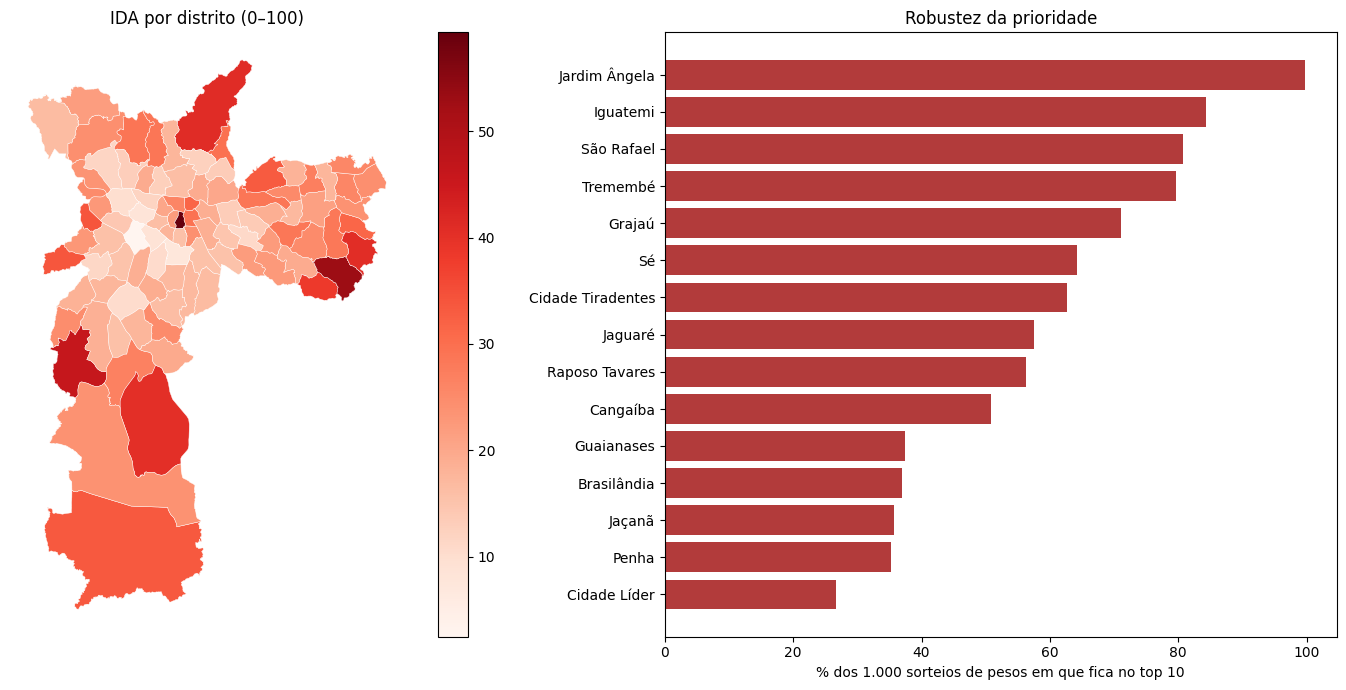

In [16]:
g = distritos[['cod_distrito', 'geometry']].merge(base, on='cod_distrito')
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
g.plot('ida', cmap='Reds', legend=True, ax=ax[0], edgecolor='white', linewidth=.3)
ax[0].set_title('IDA por distrito (0–100)'); ax[0].axis('off')
t = base.sort_values('pct_top10').tail(15)
ax[1].barh(t.nome_distrito, t.pct_top10, color='#b23b3b')
ax[1].set_xlabel('% dos 1.000 sorteios de pesos em que fica no top 10'); ax[1].set_title('Robustez da prioridade')
plt.tight_layout(); plt.show()

## P5. Perfis de território — *que tipo de ação cada grupo de distritos pede?*
K-means com variáveis padronizadas (z-score), k de 3 a 5 escolhido pela maior silhueta. Cada grupo recebe um nome automático pela variável em que mais se destaca e uma ação sugerida (edite os textos de `ACOES` se quiser).

In [17]:
VARS_CLUSTER = [v for v in ['cad_por_mil', 'dist_cras_km', 'dist_ubs_km', 'dist_cartorio_km',
                            'dist_poupatempo_km', 'pct_risco_alto'] if v in base]
Z = StandardScaler().fit_transform(base[VARS_CLUSTER].fillna(base[VARS_CLUSTER].median()))

sil = {}
for k in range(3, 6):
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Z)
    sil[k] = silhouette_score(Z, km.labels_)
print('silhueta por k:', {k: round(v, 3) for k, v in sil.items()})
K = max(sil, key=sil.get)
km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(Z)
base['cluster_id'] = km.labels_

ROTULO = {'cad_por_mil': 'Alta demanda social', 'dist_cras_km': 'Longe do CRAS', 'dist_ubs_km': 'Longe da UBS',
          'dist_cartorio_km': 'Longe de cartório', 'dist_poupatempo_km': 'Longe do Poupatempo',
          'pct_risco_alto': 'Risco geológico alto'}
ACOES = {'Alta demanda social': 'Mutirão de cadastro e atualização do CadÚnico',
         'Longe do CRAS': 'CRAS itinerante / busca ativa',
         'Longe da UBS': 'Parceria com agentes comunitários de saúde',
         'Longe de cartório': 'Mutirão de 2ª via de certidões',
         'Longe do Poupatempo': 'Mutirão de RG/CIN e CPF',
         'Risco geológico alto': 'Busca ativa com Defesa Civil nas áreas de risco',
         'Bem atendido': 'Manter monitoramento',
         'Intermediário': 'Divulgação do app e orientação'}

zc = pd.DataFrame(Z, columns=VARS_CLUSTER).groupby(base.cluster_id).mean()
nomes = {}
for cid, linha in zc.iterrows():
    top = linha.idxmax()
    nomes[cid] = ROTULO[top] if linha[top] > 0.5 else ('Bem atendido' if (linha < 0).all() else 'Intermediário')
base['cluster'] = base.cluster_id.map(lambda c: f'{c + 1} · {nomes[c]}')
base['acao_sugerida'] = base.cluster_id.map(lambda c: ACOES[nomes[c]])

print(f'k escolhido = {K}')
display(zc.round(2).assign(perfil=[nomes[c] for c in zc.index], n=base.cluster_id.value_counts().sort_index()))
display(base.groupby('cluster')[VARS_CLUSTER + ['ida']].mean().round(2))

silhueta por k: {3: np.float64(0.28), 4: np.float64(0.231), 5: np.float64(0.24)}
k escolhido = 3


,cad_por_mil,dist_cras_km,dist_ubs_km,dist_cartorio_km,dist_poupatempo_km,pct_risco_alto,perfil,n
cluster_id,,,,,,,,
0,1.12,0.99,5.85,5.65,5.95,-0.43,Longe do Poupatempo,1
1,-0.36,-0.03,-0.03,-0.38,-0.40,-0.36,Bem atendido,66
2,0.78,0.03,-0.13,0.67,0.70,0.83,Risco geológico alto,29


,cad_por_mil,dist_cras_km,dist_ubs_km,dist_cartorio_km,dist_poupatempo_km,pct_risco_alto,ida
cluster,,,,,,,
1 · Longe do Poupatempo,231.93,3.17,3.16,13.84,29.10,0.01,33.46
2 · Bem atendido,110.38,2.01,0.62,1.54,3.50,0.07,17.84
3 · Risco geológico alto,204.28,2.08,0.58,3.69,7.95,0.99,30.39


## P6. Pontos quentes — *os distritos críticos estão vizinhos uns dos outros?*
Moran global do IDA (há agrupamento espacial?) e LISA por distrito: **Alto-Alto** = distrito crítico cercado de críticos (mancha para ação regional), **Baixo-Baixo**, e os atípicos. Vizinhança Queen, 999 permutações, p < 0,05.

Moran global I = 0.286 | p = 0.001 -> há agrupamento espacial


,count
lisa_tipo,
Não significativo,74
Baixo-Baixo,14
Alto-Alto,7
Baixo-Alto,1


,nome_distrito,subprefeitura,ida,rank_ida
46,Iguatemi,São Mateus,52.97,2
68,Cidade Tiradentes,Cidade Tiradentes,40.85,5
45,São Rafael,São Mateus,38.22,7
40,Brás,Mooca,29.43,15
94,José Bonifácio,Itaquera,28.41,20
93,Parque do Carmo,Itaquera,25.04,29
67,Parelheiros,Parelheiros,23.79,34


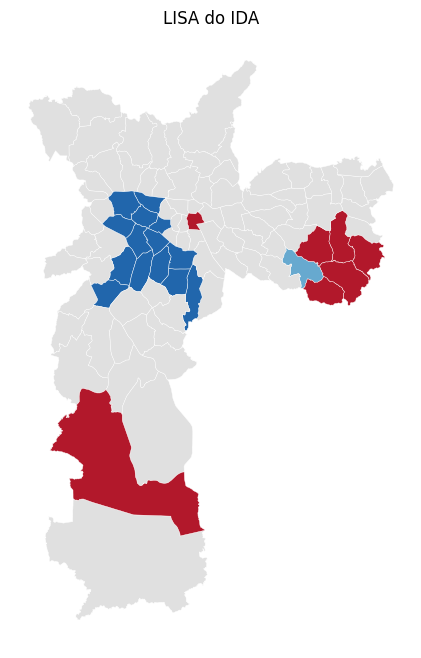

In [18]:
gm = distritos[['cod_distrito', 'geometry']].merge(base[['cod_distrito', 'ida']], on='cod_distrito').reset_index(drop=True)
try:
    w = Queen.from_dataframe(gm, use_index=False)
except TypeError:
    w = Queen.from_dataframe(gm)
if w.islands:
    print('ilhas na vizinhança Queen:', w.islands, '-> usando contiguidade com tolerância de 10 m')
    w = fuzzy_contiguity(gm, buffering=True, buffer=10)
w.transform = 'r'

mi = Moran(gm.ida, w, permutations=999)
print(f'Moran global I = {mi.I:.3f} | p = {mi.p_sim:.3f} ->',
      'há agrupamento espacial' if mi.p_sim < 0.05 else 'sem agrupamento significativo')

lisa = Moran_Local(gm.ida, w, permutations=999, seed=SEED)
Q = {1: 'Alto-Alto', 2: 'Baixo-Alto', 3: 'Baixo-Baixo', 4: 'Alto-Baixo'}
gm['lisa_tipo'] = np.where(lisa.p_sim < 0.05, pd.Series(lisa.q).map(Q), 'Não significativo')
gm['lisa_p'] = lisa.p_sim.round(4)
base = base.drop(columns=['lisa_tipo', 'lisa_p'], errors='ignore').merge(gm[['cod_distrito', 'lisa_tipo', 'lisa_p']], on='cod_distrito')
kpi['moran_I'], kpi['moran_p'] = round(mi.I, 4), round(mi.p_sim, 4)

display(base.lisa_tipo.value_counts())
display(base[base.lisa_tipo == 'Alto-Alto'][['nome_distrito', 'subprefeitura', 'ida', 'rank_ida']].sort_values('rank_ida'))
cores = {'Alto-Alto': '#b2182b', 'Baixo-Baixo': '#2166ac', 'Alto-Baixo': '#ef8a62', 'Baixo-Alto': '#67a9cf', 'Não significativo': '#e0e0e0'}
ax = gm.plot(color=gm.lisa_tipo.map(cores), edgecolor='white', linewidth=.3, figsize=(7, 8))
ax.set_title('LISA do IDA'); ax.axis('off'); plt.show()

## P7. Tendência do CadÚnico — *onde a demanda está crescendo?*
Precisa de **pelo menos 3 meses** de CadÚnico por distrito. Baixe no Observatório da SMADS os meses de 2022 a 2026 (pelo menos janeiro de cada ano, idealmente todos) e salve com o mesmo padrão de nome: `smads_cadunico_distrito_AAAA-MM.csv`. Com um arquivo só, a coluna fica como *Sem série histórica*.

In [19]:
arqs = sorted(glob.glob(os.path.join(PASTA, 'smads_cadunico_distrito_*.csv')))
print('meses encontrados:', [os.path.basename(a) for a in arqs])
base['var_12m_pct'] = np.nan; base['inclinacao_mes'] = np.nan; base['tendencia'] = 'Sem série histórica'

if len(arqs) >= 3:
    serie = []
    for a in arqs:
        ano, mes = map(int, re.search(r'(\d{4})-(\d{2})', a).groups())
        ARQ['_tmp'] = os.path.basename(a)
        t = ler_tabela('_tmp')
        cn = COL['cad_nome'] or col_de_nomes(t)
        cv = COL['cad_valor'] or C_VAL_CAD
        t['chave'] = t[cn].map(casar_nome); t['valor'] = para_num(t[cv])
        t = t.dropna(subset=['chave']).groupby('chave', as_index=False).valor.sum()
        t['data'] = pd.Timestamp(ano, mes, 1)
        serie.append(t)
    serie = pd.concat(serie)
    serie['t'] = (serie.data.dt.year - serie.data.dt.year.min()) * 12 + serie.data.dt.month
    res = []
    for k, s in serie.groupby('chave'):
        s = s.sort_values('data')
        r = linregress(s.t, s.valor)
        ult = s.iloc[-1]; ant = s[s.data == ult.data - pd.DateOffset(months=12)]
        var12 = (ult.valor / ant.valor.iloc[0] - 1) * 100 if len(ant) else np.nan
        rel = r.slope * 12 / s.valor.mean() * 100        # % ao ano
        tend = 'Crescendo' if (r.pvalue < 0.05 and rel > 2) else 'Caindo' if (r.pvalue < 0.05 and rel < -2) else 'Estável'
        res.append((k, var12, r.slope, tend))
    res = pd.DataFrame(res, columns=['chave', 'var_12m_pct', 'inclinacao_mes', 'tendencia'])
    res = res.merge(dim_distrito[['chave', 'cod_distrito']])
    base = base.drop(columns=['var_12m_pct', 'inclinacao_mes', 'tendencia']).merge(
        res.drop(columns='chave'), on='cod_distrito', how='left')
    base['tendencia'] = base.tendencia.fillna('Sem série histórica')
    fato_cadunico_mensal = serie.merge(dim_distrito[['chave', 'cod_distrito']])[['cod_distrito', 'data', 'valor']]
    salvar(fato_cadunico_mensal, 'fato_cadunico_mensal')
    display(base.tendencia.value_counts())
else:
    print('Série insuficiente: P7 não calculada (coluna tendencia = "Sem série histórica").')

meses encontrados: ['smads_cadunico_distrito_2026-01.csv']
Série insuficiente: P7 não calculada (coluna tendencia = "Sem série histórica").


## P8. Funil real dos CRAS (site indisponível no momento)
Não há arquivo de atendimentos (RMA/CRAS) na pasta. Se baixarem, as taxas (atendimento → encaminhamento → acompanhamento) devem ficar como **medidas DAX** no Power BI; o Python só confere os totais. Modelo de medida:
```
Taxa encaminhamento = DIVIDE(SUM(fato_cras[encaminhamentos]), SUM(fato_cras[atendimentos]))
```

## P9. Pesquisa própria (opcional)
Se exportarem as respostas do Google Forms como CSV para a pasta `Dados`, informe o nome abaixo. Calcula o % por resposta com **intervalo de confiança de Wilson** (adequado para amostra pequena).

In [20]:
ARQ_PESQUISA = None   # ex.: 'pesquisa_forms.csv'
if ARQ_PESQUISA:
    from statsmodels.stats.proportion import proportion_confint
    ARQ['pesquisa'] = ARQ_PESQUISA
    pq = ler_tabela('pesquisa')
    linhas = []
    for c in pq.columns:
        if re.search('CARIMBO|TIMESTAMP|EMAIL|NOME', norm(c) or ''):
            continue
        s = pq[c].dropna().astype(str).str.split(r',\s*').explode()   # múltipla escolha
        if s.nunique() > 15 or len(s) == 0:
            continue                                                  # texto livre
        n = pq[c].notna().sum()
        for resp, x in s.value_counts().items():
            lo, hi = proportion_confint(x, n, alpha=0.05, method='wilson')
            linhas.append((c, resp, x, n, x / n * 100, lo * 100, hi * 100))
    fato_pesquisa = pd.DataFrame(linhas, columns=['pergunta', 'resposta', 'qtd', 'n', 'pct', 'ic95_inf', 'ic95_sup']).round(1)
    salvar(fato_pesquisa, 'fato_pesquisa')
    display(fato_pesquisa)

## P10. Eventos simulados do app (D14) — desligado
**Só ligue se a professora aprovar o uso de dados fictícios.** Gera eventos com semente fixa: volume por distrito proporcional ao CadÚnico (D1) e proporções de documento/canal da pesquisa (D13) — preencha os dicionários com os percentuais reais da pesquisa. Toda linha sai marcada `origem = 'Simulado'`.

In [21]:
GERAR_EVENTOS = False
N_EVENTOS = 20000
PROP_DOCUMENTO = {'Certidão de nascimento': .25, 'RG/CIN': .30, 'CPF': .15, 'Comprovante de residência': .20, 'Título de eleitor': .10}
PROP_CANAL = {'App (celular próprio)': .35, 'App (celular de pessoa de confiança)': .25, 'Agente de saúde': .25, 'Assistente social/CRAS': .15}

if GERAR_EVENTOS:
    rng = np.random.default_rng(SEED)
    p = (base.cadunico / base.cadunico.sum()).values
    idx = rng.choice(len(base), size=N_EVENTOS, p=p)
    datas = pd.Timestamp('2026-05-01') + pd.to_timedelta(rng.integers(0, 184, N_EVENTOS), unit='D')
    fato_evento_app = pd.DataFrame({
        'id_evento': np.arange(1, N_EVENTOS + 1),
        'cod_distrito': base.cod_distrito.values[idx],
        'data': datas.date,
        'documento_pendente': rng.choice(list(PROP_DOCUMENTO), N_EVENTOS, p=list(PROP_DOCUMENTO.values())),
        'canal': rng.choice(list(PROP_CANAL), N_EVENTOS, p=list(PROP_CANAL.values())),
        'origem': 'Simulado'})
    salvar(fato_evento_app, 'fato_evento_app')
    display(fato_evento_app.head())

## Exportação para o Power BI (star schema)
```
dim_subprefeitura (subprefeitura, email_gestor) 1 ─── * dim_distrito
dim_distrito (cod_distrito, subprefeitura)  1 ─── *  fato_beneficios_distrito
                                            1 ─── *  fato_indicadores_distrito / fato_lacuna_programa / fato_recomendacoes (Modelo_GS)
                                            1 ─── *  fato_acesso_distrito_servico
                                            1 ─── *  fato_risco_setor
                                            1 ─── *  dim_equipamento (CRAS, UBS, cartório, Poupatempo: a "unidade" do app)
                                            1 ─── *  fato_evento_app / fato_cadunico_mensal (se houver)
```
CSV com `;` e vírgula decimal (Power BI em português lê direto). O mapa sai em TopoJSON (`distritos_sp.topojson`), o formato do visual Mapa de formas. O IDA (`fato_indice_ida`) fica em `saida/extras` e não entra no painel. Para cada gestor ver só a sua subprefeitura, use **RLS** em `dim_subprefeitura[email_gestor]`.

Hierarquia igual à do app: **subprefeitura → distrito → unidade**. A unidade (UBS/CRAS) em que o agente se cadastra é uma linha de `dim_equipamento` (`eh_unidade_app = True`).

Arquivos de versões antigas que ainda estiverem em `saida/` são movidos para `saida/antigos/`, para não entrarem no Power BI por engano.

In [23]:
# ---- limpa saida/: arquivos de versões antigas do tratamento e do modelo vão para saida/antigos ----
import shutil
ANTIGOS = ['dim_servico.csv', 'dim_campanha.csv', 'fato_modelo_distrito.csv', 'fato_recomendacao.csv',
           'kpi_modelo.csv', 'modelo_comparacao.csv', 'modelo_importancia.csv', 'fato_indice_distrito.csv']
os.makedirs(os.path.join(SAIDA, 'antigos'), exist_ok=True)
for a in ANTIGOS:
    if os.path.exists(os.path.join(SAIDA, a)):
        shutil.move(os.path.join(SAIDA, a), os.path.join(SAIDA, 'antigos', a))
        print('  movido para saida/antigos:', a)

fato_indice = base[['cod_distrito', 'cadunico', 'cad_por_mil', 'dist_cras_km', 'pct_risco_alto', 'moradias_r3r4',
                    'n_cad_por_mil', 'n_dist_cras_km', 'n_pct_risco_alto', 'ida', 'rank_ida',
                    'vezes_top10', 'pct_top10', 'prioridade', 'cluster', 'acao_sugerida',
                    'lisa_tipo', 'lisa_p', 'var_12m_pct', 'inclinacao_mes', 'tendencia']].copy()
fato_indice['origem'] = 'Dados públicos'

salvar(dim_distrito[['cod_distrito', 'nome_distrito', 'subprefeitura', 'area_km2', 'pop_2022', 'densidade_hab_km2']].round(3), 'dim_distrito')
# dim_equipamento: mesmo nome do modelo conceitual do app (a "unidade" do agente é uma linha daqui)
dim_equipamento = dim_servico.rename(columns={'id_servico': 'id_equipamento', 'tipo_servico': 'tipo_equipamento',
                                              'nome_servico': 'nome_equipamento'})
dim_equipamento['eh_unidade_app'] = dim_equipamento.tipo_equipamento.isin(['CRAS', 'UBS'])
# só o que fica no município (os pontos de cidades vizinhas servem para a distância, não como unidade do app)
fora = dim_equipamento.cod_distrito.isna()
print(f'  dim_equipamento: {fora.sum()} pontos fora do município removidos')
dim_equipamento = dim_equipamento[~fora]
# mesmo equipamento cadastrado duas vezes (ex.: CRAS - Rua Henrique Jacobs, 788)
dup = dim_equipamento.duplicated(['tipo_equipamento', 'nome_equipamento'])
print(f'  dim_equipamento: {dup.sum()} duplicados removidos')
dim_equipamento = dim_equipamento[~dup]
# Padroniza cod_distrito como inteiro nas duas tabelas
dim_equipamento['cod_distrito'] = pd.to_numeric(
    dim_equipamento['cod_distrito'], errors='coerce'
).astype('Int64')

dim_distrito['cod_distrito'] = pd.to_numeric(
    dim_distrito['cod_distrito'], errors='coerce'
).astype('Int64')

# Relaciona os equipamentos com suas respectivas subprefeituras
dim_equipamento = dim_equipamento.merge(
    dim_distrito[['cod_distrito', 'subprefeitura']],
    on='cod_distrito',
    how='left',
    validate='many_to_one'
)
salvar(dim_equipamento[['id_equipamento', 'tipo_equipamento', 'nome_equipamento', 'eh_unidade_app',
                        'cod_distrito', 'subprefeitura', 'lat', 'lon']], 'dim_equipamento')
salvar(fato_acesso, 'fato_acesso_distrito_servico')
salvar(fato_risco_setor, 'fato_risco_setor')
# IDA / cluster / LISA NÃO vão para o Power BI: no painel, a prioridade e as campanhas vêm só do
# Modelo_GS (fato_indicadores_distrito e fato_recomendacoes). Duas prioridades no mesmo painel se contradiriam.
# A tabela fica em saida/extras/ só para consulta do grupo.
os.makedirs(os.path.join(SAIDA, 'extras'), exist_ok=True)
fato_indice.round(4).to_csv(os.path.join(SAIDA, 'extras', 'fato_indice_ida.csv'), sep=';', decimal=',', index=False, encoding='utf-8-sig')
print('  IDA salvo só em saida/extras/fato_indice_ida.csv (fora do Power BI)')

# kpi_cidade: as contagens de serviços vêm da dim_equipamento já limpa (sem pontos de fora e sem duplicados),
# para o site e o painel mostrarem o mesmo número de CRAS, UBS, cartórios e Poupatempo
for k, tipo in {'qtd_cras': 'CRAS', 'qtd_ubs': 'UBS', 'qtd_cartorios': 'Cartório', 'qtd_poupatempo': 'Poupatempo'}.items():
    kpi[k] = int(dim_equipamento.tipo_equipamento.eq(tipo).sum())
# kpi_cidade: tira o que não deve aparecer no painel
kpi_pbi = {k: v for k, v in kpi.items() if not k.startswith('moran')}           # estatísticas do IDA
if kpi_pbi.get('cde_desconto_enel_sp_rs', 1) == 0:                               # arquivo da ANEEL sem a Enel SP
    kpi_pbi.pop('cde_desconto_enel_sp_rs')
salvar(pd.DataFrame([kpi_pbi]).round(4), 'kpi_cidade')

# dim_subprefeitura: 32 linhas, com email_gestor para a segurança por linha (RLS).
# Preencham os e-mails no CSV; se ele já existir, os e-mails preenchidos são mantidos.
dim_subprefeitura = pd.DataFrame({'subprefeitura': list(SUBPREF),
                                  'qtd_distritos': [len(v) for v in SUBPREF.values()], 'email_gestor': ''})
arq_sub = os.path.join(SAIDA, 'dim_subprefeitura.csv')
if os.path.exists(arq_sub):
    antigo = pd.read_csv(arq_sub, sep=';', encoding='utf-8-sig', dtype=str).fillna('')
    dim_subprefeitura['email_gestor'] = dim_subprefeitura.subprefeitura.map(antigo.set_index('subprefeitura').email_gestor).fillna('')
assert set(dim_distrito.subprefeitura) <= set(dim_subprefeitura.subprefeitura), 'subprefeitura sem par'
salvar(dim_subprefeitura, 'dim_subprefeitura')

mapa = distritos[['cod_distrito', 'nome_distrito', 'subprefeitura', 'geometry']].copy()
mapa['geometry'] = mapa.simplify(20)
mapa.to_crs(CRS_MAPA).to_file(os.path.join(SAIDA, 'distritos_sp.geojson'), driver='GeoJSON')
print('  salvo distritos_sp.geojson')

# O visual "Mapa de formas" do Power BI só aceita TopoJSON
try:
    try:
        import topojson as tp
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'topojson'], check=True)
        import topojson as tp
    topo = tp.Topology(mapa.to_crs(CRS_MAPA), prequantize=True, object_name='distritos')
    with open(os.path.join(SAIDA, 'distritos_sp.topojson'), 'w', encoding='utf-8') as f:
        f.write(topo.to_json())
    print('  salvo distritos_sp.topojson (use no Mapa de formas, chave = cod_distrito)')
except Exception as e:
    print('  TopoJSON não gerado:', repr(e), '-> converta o distritos_sp.geojson em mapshaper.org (Export > TopoJSON)')

  salvo dim_distrito.csv  (96 linhas)
  dim_equipamento: 32 pontos fora do município removidos
  dim_equipamento: 2 duplicados removidos
  salvo dim_equipamento.csv  (670 linhas)
  salvo fato_acesso_distrito_servico.csv  (384 linhas)
  salvo fato_risco_setor.csv  (1480 linhas)
  IDA salvo só em saida/extras/fato_indice_ida.csv (fora do Power BI)
  salvo kpi_cidade.csv  (1 linhas)
  salvo dim_subprefeitura.csv  (32 linhas)
  salvo distritos_sp.geojson
  salvo distritos_sp.topojson (use no Mapa de formas, chave = cod_distrito)


## Novas bases: CadÚnico por renda, Bolsa Família, BPC e idade + `distritos_base.csv`
Lê os 3 `.ods` do Portal de Dados Abertos SP e o Censo 2022 por idade (TabNet), casa os nomes com os 96 distritos e junta com população, distância ao CRAS e risco. Salva `fato_beneficios_distrito.csv` (Power BI) e `distritos_base.csv` (entrada do Modelo_GS). Confira o que a célula imprime: aba e coluna usadas em cada base, e os totais da cidade.

In [24]:
# ------------------------------------------------------------------
# NOVAS BASES (Portal de Dados Abertos SP) + BASE DO MODELO: saida/distritos_base.csv
# ------------------------------------------------------------------
# Arquivos .ods precisam do odfpy (no Colab: !pip install odfpy)
try:
    import odf  # noqa: F401
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'odfpy'], check=True)

ARQ.update({
    'cad_ods': '2026.01-ods-familias-cadastradas-no-cadunico-por-distrito.ods',
    'pbf':     'bolsa-familia-distrito_2025.ods',
    'bpc':     'prestacao-continua_julho_2025_xls1.ods',
    # Censo 2022 por distrito e faixa etária (TabNet SMS-SP: linha = Dist Adm (DA), coluna = Faixa Etária)
    'idade':   'censo2022_faixa-etaria_distrito.csv',
})
# Deixe None para detecção automática. Se a inspeção mostrar erro, escreva o nome exato.
COL.update({'pbf_valor': None, 'bpc_idoso': None, 'bpc_pcd': None, 'cad_pobreza': None})

MESES = ['JAN', 'FEV', 'MAR', 'ABR', 'MAI', 'JUN', 'JUL', 'AGO', 'SET', 'OUT', 'NOV', 'DEZ']

def num_misto(s):
    # .ods traz números já como número; texto ('1.234') passa pelo para_num
    eh_num = s.map(lambda x: isinstance(x, (int, float, np.integer, np.floating)) and not isinstance(x, bool))
    out = pd.to_numeric(s.where(eh_num), errors='coerce')
    if (~eh_num & s.notna()).any():
        out = out.fillna(para_num(s.where(~eh_num).astype(str)))
    return out

def preparar(t, rotulo):
    """Acha a coluna de distrito, converte o resto em número e soma por distrito (None se não for tabela de distritos)."""
    t = t.dropna(axis=1, how='all')   # colunas só com cabeçalho (ex.: mês ainda sem dado)
    c_nome = col_de_nomes(t)
    if c_nome is None:
        return None
    t = t.copy()
    t['chave'] = t[c_nome].map(casar_nome)
    t = t.dropna(subset=['chave'])
    if t.chave.nunique() < 80:          # aba de resumo (subprefeitura, macrorregião, cidade...)
        return None
    for c in t.columns:
        if c not in (c_nome, 'chave'):
            v = num_misto(t[c])
            if v.notna().mean() > 0.8:
                t[c] = v
    num = [c for c in t.columns if t[c].dtype.kind in 'if']
    print(f'{rotulo}: {t.chave.nunique()} distritos | distrito = "{c_nome}" | números: {num[:12]}{" ..." if len(num) > 12 else ""}')
    if t.chave.duplicated().any():
        print('   mais de uma linha por distrito -> somando')
    return t.groupby('chave', as_index=False)[num].sum()

def ler_brutas(chave):
    caminho = os.path.join(PASTA, ARQ[chave])
    if not os.path.exists(caminho):
        print(f'FALTA {ARQ[chave]} na pasta Dados')
        return {}
    if caminho.lower().endswith(('.ods', '.xlsx', '.xls')):
        return pd.read_excel(caminho, sheet_name=None, header=None,
                             engine='odf' if caminho.lower().endswith('.ods') else None)
    return {'csv': ler_csv_bruto(caminho)}

def abas_por_distrito(chave):
    """Lê todas as abas (xlsx/ods/csv) e devolve {aba: tabela por distrito} só com as abas que têm os distritos."""
    saida = {}
    for aba, raw in ler_brutas(chave).items():
        if raw.dropna(how='all').empty:
            continue
        t = preparar(com_cabecalho(raw), f'{ARQ[chave]} | aba "{aba}"')
        if t is not None:
            saida[aba] = t
    if not saida and os.path.exists(os.path.join(PASTA, ARQ[chave])):
        print(f'{ARQ[chave]}: nenhuma aba com os 96 distritos — veja o arquivo e ajuste')
    return saida

def coluna_mais_recente(t):
    """Se as colunas forem meses (jan, fev... ou datas), devolve o último mês preenchido."""
    mensais = [c for c in t.columns if c != 'chave'
               and (any(m in (norm(c) or '') for m in MESES) or re.search(r'20\d\d[-/]\d\d|\d\d/20\d\d', str(c)))]
    mensais = [c for c in mensais if t[c].notna().mean() > 0.9 and 'TOTAL' not in (norm(c) or '')]
    return mensais[-1] if mensais else None

base_modelo = dim_distrito[['cod_distrito', 'chave', 'nome_distrito', 'subprefeitura', 'pop_2022', 'cadunico']].rename(
    columns={'nome_distrito': 'distrito', 'pop_2022': 'pop_total', 'cadunico': 'familias_cadunico'})
base_modelo['dist_cras_km'] = base_modelo.cod_distrito.map(dist_wide['dist_cras_km'])
base_modelo['setores_risco_r3r4'] = base_modelo.cod_distrito.map(risco_d.set_index('cod_distrito').qtd_setores_r3r4)

# --- CadÚnico (.ods): total de famílias e, se houver, faixa de renda ---
cad_ods = abas_por_distrito('cad_ods')
if cad_ods:
    t = next(iter(cad_ods.values()))
    num = [c for c in t.columns if c != 'chave']
    c_tot = col_por_nome(t[num], 'TOTAL') or col_por_nome(t[num], 'FAMIL')
    if c_tot:
        dif = (base_modelo.chave.map(t.set_index('chave')[c_tot]) - base_modelo.familias_cadunico).abs().sum()
        print(f'CadÚnico .ods "{c_tot}" vs CSV usado no tratamento: diferença total = {dif:,.0f}')
    # pobreza = extrema pobreza + pobreza (até meio salário mínimo NÃO entra: é baixa renda)
    c_pob = COL['cad_pobreza'] or [c for c in num if re.search(r'POBREZA', norm(c) or '')]
    if isinstance(c_pob, str):
        c_pob = [c_pob]
    if c_pob:
        print('famílias em pobreza = soma de', c_pob)
        base_modelo['familias_cadunico_pobreza'] = base_modelo.chave.map(t.set_index('chave')[c_pob].sum(axis=1))
    else:
        print('o .ods do CadÚnico não traz faixa de renda -> o modelo usa o total do CadÚnico na cobertura do PBF')

# --- Bolsa Família ---
pbf = abas_por_distrito('pbf')
if pbf:
    t = next(iter(pbf.values()))
    num = [c for c in t.columns if c != 'chave']
    c = COL['pbf_valor'] or coluna_mais_recente(t) or col_por_nome(t[num], 'FAMIL') or num[0]
    print('Bolsa Família: usando a coluna', repr(c))
    base_modelo['familias_pbf'] = base_modelo.chave.map(t.set_index('chave')[c])

# --- BPC (julho/2025): idoso e PcD podem vir em colunas ou em abas separadas ---
bpc = abas_por_distrito('bpc')
if bpc:
    def pega(tipo_chaves):
        for aba, t in bpc.items():
            num = [c for c in t.columns if c != 'chave']
            c = col_por_nome(t[num], *tipo_chaves)
            if c:
                return t.set_index('chave')[c], f'aba "{aba}", coluna "{c}"'
            if any(k in (norm(aba) or '') for k in tipo_chaves):
                c = col_por_nome(t[num], 'TOTAL', 'BENEF', 'QTD') or num[-1]
                return t.set_index('chave')[c], f'aba "{aba}", coluna "{c}"'
        return None, None
    s_id, onde_id = (bpc[next(iter(bpc))].set_index('chave')[COL['bpc_idoso']], 'COL') if COL['bpc_idoso'] else pega(('IDOS',))
    s_pcd, onde_pcd = (bpc[next(iter(bpc))].set_index('chave')[COL['bpc_pcd']], 'COL') if COL['bpc_pcd'] else pega(('DEFIC', 'PCD', 'PESSOA COM'))
    print('BPC idoso ->', onde_id, '| BPC PcD ->', onde_pcd)
    if s_id is not None:
        base_modelo['bpc_idoso'] = base_modelo.chave.map(s_id)
    if s_pcd is not None:
        base_modelo['bpc_pcd'] = base_modelo.chave.map(s_pcd)

# --- idade (Censo 2022, TabNet SMS-SP) ---
# Exportar com Linha = "Distrito Administrativo" e Coluna = "Idade" (idade simples) ou "Faixa Etária".
# Também aceita a tabela "virada" (linha = idade, coluna = distrito).
def idade_de(c):
    txt = str(c)
    if '<' in txt:                       # "< 1 ano"
        return 0
    m = re.match(r'\D*(\d+)', txt)            # "65 a 69", "80 e mais", "07 anos", "100 anos e +"
    return int(m.group(1)) if m else None

# Totais da cidade no TabNet (Censo 2022 ajustado para 1º de julho): 65+ por faixa etária e 0–6 por idade simples
POP_65_CIDADE, POP_0_6_CIDADE = 1_381_829, 869_479
idade = None
for aba, raw in ler_brutas('idade').items():
    t = com_cabecalho(raw).dropna(axis=1, how='all')
    if sum(casar_nome(c) is not None for c in t.columns) >= 80:      # linha = idade, coluna = distrito
        t = t.set_index(t.columns[0]).T.reset_index().rename(columns={'index': 'Distrito'})
    idade = preparar(t, f'{ARQ["idade"]} | aba "{aba}"')
    if idade is not None:
        break
if idade is None and os.path.exists(os.path.join(PASTA, ARQ['idade'])):
    print('O arquivo de idade não tem os distritos (parece ser só o total da cidade).\n'
          'No TabNet, escolha Linha = "Distrito Administrativo" e Coluna = "Idade", e exporte de novo.')
if idade is not None:
    faixas = {c: idade_de(c) for c in idade.columns if c != 'chave' and 'TOTAL' not in (norm(c) or '')}
    faixas = {c: i for c, i in faixas.items() if i is not None}
    print('idades/faixas reconhecidas:', len(faixas), '| exemplo:', dict(list(faixas.items())[:4]))
    t = idade.set_index('chave')
    base_modelo['pop_65_mais'] = base_modelo.chave.map(t[[c for c, i in faixas.items() if i >= 65]].sum(axis=1))
    print(f'65+: soma dos distritos = {base_modelo.pop_65_mais.sum():,.0f} | cidade no Censo = {POP_65_CIDADE:,}')
    simples = [c for c, i in faixas.items() if i <= 6 and not re.search(r'\d+\D+\d+', str(c))]
    if len({faixas[c] for c in simples}) == 7:            # idade simples 0..6 -> dá para ter 0–6
        base_modelo['pop_0_6'] = base_modelo.chave.map(t[simples].sum(axis=1))
        print(f'0–6: soma dos distritos = {base_modelo.pop_0_6.sum():,.0f} | cidade no Censo = {POP_0_6_CIDADE:,}')
    else:
        print('0–6: o arquivo está em faixas de 5 anos, sem idade simples -> pop_0_6 fica fora (o modelo funciona sem)')

# --- conferências e gravação ---
print()
for c in ['familias_cadunico_pobreza', 'familias_pbf', 'bpc_idoso', 'bpc_pcd', 'pop_65_mais', 'pop_0_6']:
    if c in base_modelo:
        print(f'{c:28s} distritos com dado: {base_modelo[c].notna().sum():3d}/96 | total cidade: {base_modelo[c].sum():,.0f}')
checks = {
    'PBF <= CadÚnico': ('familias_pbf' in base_modelo) and (base_modelo.familias_pbf <= base_modelo.familias_cadunico).all(),
    'BPC idoso <= 65+': ('pop_65_mais' in base_modelo) and ('bpc_idoso' in base_modelo) and (base_modelo.bpc_idoso <= base_modelo.pop_65_mais).all(),
}
for k, v in checks.items():
    print(('OK   ' if v else 'FALHA/sem dado'), k)

# tabela tratada das novas bases para o Power BI (mesmo padrão ; e vírgula)
cols_novas = [c for c in ['familias_cadunico_pobreza', 'familias_pbf', 'bpc_idoso', 'bpc_pcd', 'pop_65_mais', 'pop_0_6'] if c in base_modelo]
salvar(base_modelo[['cod_distrito'] + cols_novas], 'fato_beneficios_distrito')

faltam_cols = [c for c in ['pop_65_mais', 'familias_pbf', 'bpc_idoso'] if c not in base_modelo or base_modelo[c].isna().any()]
if faltam_cols:
    print('\nNÃO GEREI distritos_base.csv: faltam (ou estão incompletas)', faltam_cols)
else:
    # CSV padrão (vírgula/ponto): é entrada do Python (Modelo_GS), não do Power BI
    base_modelo.drop(columns='chave').to_csv(os.path.join(SAIDA, 'distritos_base.csv'), index=False)
    print('\nsalvo distritos_base.csv', base_modelo.shape)
display(base_modelo.head())


2026.01-ods-familias-cadastradas-no-cadunico-por-distrito.ods | aba "Quant__Macrorreg_,_Sub__e_Dist_": 96 distritos | distrito = "DISTRITO" | números: ['TOTAL DE FAMÍLIAS']
CadÚnico .ods "TOTAL DE FAMÍLIAS" vs CSV usado no tratamento: diferença total = 0
o .ods do CadÚnico não traz faixa de renda -> o modelo usa o total do CadÚnico na cobertura do PBF
bolsa-familia-distrito_2025.ods | aba "Table_1": 96 distritos | distrito = "DISTRITOS" | números: ['TOTAL DE FAMÍLIAS']
Bolsa Família: usando a coluna 'TOTAL DE FAMÍLIAS'
prestacao-continua_julho_2025_xls1.ods | aba "BPC_JULHO_2025_-_GERAL": 96 distritos | distrito = "DISTRITOS" | números: ['BPC - PESSOAS IDOSAS', 'BPC - PESSOASCOM DEFICIÊNCIA']
prestacao-continua_julho_2025_xls1.ods | aba "BPC_JULHO_2025_-_PESSOA_IDOSA": 96 distritos | distrito = "DISTRITOS" | números: ['Total']
prestacao-continua_julho_2025_xls1.ods | aba "BPC_JULHO_2025_-_PCD": 96 distritos | distrito = "DISTRITOS" | números: ['TOTAL']
BPC idoso -> aba "BPC_JULHO_2025_

,cod_distrito,chave,distrito,subprefeitura,pop_total,familias_cadunico,dist_cras_km,setores_risco_r3r4,familias_pbf,bpc_idoso,bpc_pcd,pop_65_mais
0,63,PIRITUBA,Pirituba,Pirituba/Jaraguá,179724.0,20449,NaN,NaN,6966,2308,1215,21916.0
1,95,SAO DOMINGOS,São Domingos,Pirituba/Jaraguá,88884.0,10745,NaN,NaN,3845,1011,560,11780.0
2,42,JARAGUA,Jaraguá,Pirituba/Jaraguá,211610.0,37663,NaN,NaN,14587,2816,1865,18110.0
3,11,BRASILANDIA,Brasilândia,Freguesia/Brasilândia,243273.0,53409,NaN,NaN,21366,4339,3199,22185.0
4,29,FREGUESIA DO O,Freguesia do Ó,Freguesia/Brasilândia,137240.0,16880,NaN,NaN,5460,2067,905,20781.0


## Checagem final

In [25]:
ler = lambda n: pd.read_csv(os.path.join(SAIDA, f'{n}.csv'), sep=';', decimal=',', encoding='utf-8-sig')
dd, fa, fb, ds, de = (ler('dim_distrito'), ler('fato_acesso_distrito_servico'), ler('fato_beneficios_distrito'),
                      ler('dim_subprefeitura'), ler('dim_equipamento'))
ok = {
    'dim_distrito: 96 linhas': len(dd) == 96,
    'dim_subprefeitura: 32 linhas': len(ds) == 32,
    'fato_acesso: 96 x nº de serviços': len(fa) == 96 * fa.servico.nunique(),
    'fato_beneficios: 96 linhas': len(fb) == 96,
    'cod_distrito casa entre tabelas': set(dd.cod_distrito) == set(fa.cod_distrito) == set(fb.cod_distrito),
    'distritos_base.csv pronto para o Modelo_GS': os.path.exists(os.path.join(SAIDA, 'distritos_base.csv')),
    'mapa em TopoJSON': os.path.exists(os.path.join(SAIDA, 'distritos_sp.topojson')),
    'IDA fora da pasta do Power BI': not os.path.exists(os.path.join(SAIDA, 'fato_indice_distrito.csv')),
    'dim_equipamento: todo ponto tem distrito': de.cod_distrito.notna().all(),
    'nenhum arquivo antigo em saida/': not any(os.path.exists(os.path.join(SAIDA, a)) for a in ANTIGOS),
}
for k, v in ok.items():
    print(('OK   ' if v else 'FALHA'), k)
print('\narquivos em saida/:', sorted(os.listdir(SAIDA)))
print('e-mails de gestor preenchidos:', (ds.email_gestor.fillna('') != '').sum(), '/ 32 (preencham no dim_subprefeitura.csv para a RLS)')


OK    dim_distrito: 96 linhas
OK    dim_subprefeitura: 32 linhas
OK    fato_acesso: 96 x nº de serviços
OK    fato_beneficios: 96 linhas
OK    cod_distrito casa entre tabelas
OK    distritos_base.csv pronto para o Modelo_GS
OK    mapa em TopoJSON
OK    IDA fora da pasta do Power BI
OK    dim_equipamento: todo ponto tem distrito
OK    nenhum arquivo antigo em saida/

arquivos em saida/: ['antigos', 'dim_distrito.csv', 'dim_equipamento.csv', 'dim_subprefeitura.csv', 'distritos_base.csv', 'distritos_sp.geojson', 'distritos_sp.topojson', 'extras', 'fato_acesso_distrito_servico.csv', 'fato_beneficios_distrito.csv', 'fato_risco_setor.csv', 'kpi_cidade.csv']
e-mails de gestor preenchidos: 0 / 32 (preencham no dim_subprefeitura.csv para a RLS)
